# Pengujian Hasil Optimasi NSGA-II: Indikator *Hypervolume* dan Uji Statistik

Notebook ini mengimplementasikan bagian pengujian pada **Bab 5** skripsi: mengevaluasi kualitas
solusi yang dihasilkan `MBGOptimizer` (`nsga2_core.py`) menggunakan indikator **Hypervolume (HV)**,
lalu membandingkan beberapa konfigurasi parameter (hasil *tuning* Bab 4) secara statistik dengan
**uji Kruskal-Wallis** (perbandingan >2 kelompok) dan **uji Mann-Whitney U** (post-hoc berpasangan).

Desain eksperimen: setiap konfigurasi dijalankan **beberapa kali secara independen** (seed acak
berbeda tiap run). Ini sekaligus memenuhi dua tujuan:

1. **Perbandingan antar-konfigurasi** — apakah pilihan parameter (populasi, pc, pm, generasi) dari
   Bab 4 memberi kualitas Pareto front yang berbeda secara signifikan?
2. **Uji stabilitas/konsistensi** — seberapa besar variasi HV antar run pada konfigurasi yang sama
   (dilihat dari standar deviasi/koefisien variasi HV-nya).

> ⚠️ **Sebelum menjalankan**: lengkapi bagian *"Memuat Dataset"* dengan path CSV asli
> (`makanan.csv`, `target_gizi.csv`, `susu.csv`) dan bagian *"Konfigurasi yang Diuji"* dengan
> parameter hasil *tuning* Bab 4 yang sebenarnya. Selama data asli belum diisi, notebook memakai
> data sintetis kecil hanya agar seluruh sel bisa dijalankan dan diperiksa alurnya.

Setiap tahap pengujian di bawah dilengkapi **grafik** (disimpan sebagai PNG di `hasil_ekspor/figures/`),
dan di bagian akhir (11) seluruh **tabel + grafik** diekspor otomatis ke satu file
**`hasil_ekspor/bab5_hasil_uji_statistik.xlsx`** yang siap dilampirkan ke laporan.

## 1. Persiapan

In [60]:
import sys
import time
import itertools
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

np.set_printoptions(suppress=True)
pd.set_option("display.width", 120)

# nsga2_core.py harus berada di direktori yang sama dengan notebook ini
# (atau sesuaikan path-nya di bawah).
sys.path.append(str(Path.cwd()))
from nsga2_core import MBGOptimizer, CATEGORIES, NUT_COLS

# Folder ekspor (sama pola dengan 'hasil_ekspor/' yang sudah dipakai di notebook Bab 4)
OUTPUT_DIR = Path("hasil_ekspor")
FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
XLSX_PATH = OUTPUT_DIR / "bab5_hasil_uji_statistik.xlsx"

print("Modul nsga2_core berhasil dimuat.")
print(f"Grafik akan disimpan ke: {FIG_DIR}/")
print(f"Excel akan disimpan ke : {XLSX_PATH}")

Modul nsga2_core berhasil dimuat.
Grafik akan disimpan ke: hasil_ekspor\figures/
Excel akan disimpan ke : hasil_ekspor\bab5_hasil_uji_statistik.xlsx


## 2. Memuat Dataset

Isi `DATA_DIR` dengan folder berisi `makanan.csv`, `target_gizi.csv`, `susu.csv` (format sama
seperti yang dipakai pada notebook Bab 4 / `repository.py`). Jika file tidak ditemukan, notebook
akan otomatis memakai **data sintetis** (diberi tanda peringatan) supaya struktur eksperimen tetap
bisa diuji coba lebih dulu.

In [61]:
DATA_DIR = Path("data")  # <-- ganti sesuai lokasi CSV asli Anda

def _buat_data_sintetis(seed=0):
    '''Data contoh kecil hanya untuk menjalankan notebook tanpa dataset asli.'''
    rng = np.random.default_rng(seed)
    rows = []
    id_counter = 1
    jumlah_per_kategori = {"pokok": 12, "lauk": 20, "sayur": 15, "buah": 10}
    for kategori, n in jumlah_per_kategori.items():
        for i in range(n):
            rows.append({
                "id_makanan": id_counter,
                "kode": f"{kategori[:1].upper()}{i+1:03d}",
                "nama": f"{kategori.capitalize()} contoh {i+1}",
                "kategori": kategori,
                "berat": float(rng.integers(50, 200)),
                "energi": float(rng.integers(80, 350)),
                "protein": float(rng.integers(2, 25)),
                "lemak": float(rng.integers(1, 20)),
                "karbo": float(rng.integers(5, 60)),
            })
            id_counter += 1
    df_makanan = pd.DataFrame(rows)

    target_gizi = {
        "energi_min": 550.0, "energi_max": 700.0,
        "protein_min": 20.0, "protein_max": 30.0,
        "lemak_min": 15.0, "lemak_max": 25.0,
        "karbo_min": 70.0, "karbo_max": 100.0,
    }
    susu = {"id_menutetap": 1, "nama": "Susu UHT 200ml",
            "berat": 200.0, "energi": 130.0, "protein": 5.0, "lemak": 5.0, "karbo": 15.0}
    return df_makanan, target_gizi, susu


try:
    df_makanan = pd.read_csv(DATA_DIR / "makanan2.csv")
    target_gizi_df = pd.read_csv(DATA_DIR / "target_gizi.csv")
    target_gizi = target_gizi_df.iloc[0].to_dict()
    susu_df = pd.read_csv(DATA_DIR / "susu.csv")
    susu = susu_df.iloc[0].to_dict()
    print(f"Dataset asli dimuat dari '{DATA_DIR}/'.")
except FileNotFoundError:
    print(f"[PERINGATAN] CSV tidak ditemukan di '{DATA_DIR}/' — memakai DATA SINTETIS sementara. "
          "Ganti DATA_DIR di atas dengan dataset asli sebelum menjalankan pengujian final untuk Bab 5.")
    df_makanan, target_gizi, susu = _buat_data_sintetis()

print(f"Jumlah item per kategori: "
      f"{df_makanan['kategori'].value_counts().to_dict()}")

Dataset asli dimuat dari 'data/'.
Jumlah item per kategori: {'lauk': 125, 'sayur': 56, 'buah': 50, 'pokok': 41}


## 3. Konfigurasi yang Diuji

Daftar `CONFIGS` di bawah adalah **contoh placeholder** — ganti dengan konfigurasi parameter hasil
*tuning* 36-kombinasi pada Bab 4 (misalnya kandidat terbaik + 1-2 pembanding), agar uji statistik
ini benar-benar menjawab: *"apakah konfigurasi terpilih unggul secara signifikan?"*

`N_RUNS` adalah jumlah run independen per konfigurasi (umum dipakai 20-30 run pada literatur
pengujian algoritma evolusioner). Tiap run memakai seed berbeda agar populasi awal & operator
genetik benar-benar independen antar-run.

In [62]:
CONFIGS = [
    {"nama": "Konfigurasi A (baseline)", "pop_size": 60, "pc": 0.9, "pm": 0.1, "max_gen": 60},
    {"nama": "Konfigurasi B (mutasi tinggi)", "pop_size": 60, "pc": 0.9, "pm": 0.3, "max_gen": 60},
    {"nama": "Konfigurasi C (populasi besar)", "pop_size": 100, "pc": 0.9, "pm": 0.2, "max_gen": 60},
]  # <-- ganti dengan hasil tuning Bab 4 yang sebenarnya

N_RUNS = 20           # <-- naikkan ke 20-30 untuk hasil pengujian final di Bab 5
BASE_SEED = 1000      # basis seed; tiap (konfigurasi, run) mendapat seed unik & reproducible

print(f"{len(CONFIGS)} konfigurasi x {N_RUNS} run independen = {len(CONFIGS) * N_RUNS} total run")

3 konfigurasi x 20 run independen = 60 total run


## 4. Indikator Hypervolume (2D)

Karena `f1` (deviasi gizi) dan `f2` (penalti pengulangan) sama-sama **diminimumkan**, Hypervolume
dihitung sebagai luas wilayah pada ruang objektif yang didominasi oleh Pareto front terhadap sebuah
**titik referensi** (*reference point* / titik nadir) yang lebih buruk dari seluruh solusi yang
diamati. Semakin besar HV, semakin baik front tersebut (lebih dekat ke titik ideal *dan* lebih
beragam/menyebar).

Titik referensi dihitung **setelah semua run selesai** (lihat bagian 5) supaya seluruh HV yang
dibandingkan antar-konfigurasi memakai acuan yang sama — ini penting agar nilai HV benar-benar
komparabel.

In [63]:
def hypervolume_2d(front_points, ref_point):
    '''Hitung Hypervolume 2D untuk masalah minimisasi.

    front_points : list of (f1, f2) -- idealnya sudah non-dominated (Pareto front rank-1).
    ref_point    : (ref_f1, ref_f2) -- titik referensi, harus lebih buruk (lebih besar)
                   dari seluruh titik pada front_points.
    '''
    if not front_points:
        return 0.0
    pts = sorted(set(front_points), key=lambda p: p[0])
    ref_f1, ref_f2 = ref_point
    hv = 0.0
    prev_f1 = None
    best_f2_so_far = ref_f2
    for f1, f2 in pts:
        if f1 >= ref_f1 or f2 >= ref_f2:
            continue
        lebar = ref_f1 - f1
        tinggi = best_f2_so_far - f2
        if tinggi > 0:
            hv += lebar * tinggi
            best_f2_so_far = f2
    return float(hv)

## 5. Menjalankan Eksperimen Multi-Run

Tahap ini menjalankan `MBGOptimizer.run()` untuk setiap kombinasi konfigurasi x run, menyimpan
Pareto front rank-1 (`front1_points`) dari tiap run. Titik referensi Hypervolume ditentukan setelah
seluruh run selesai, dari nilai terburuk (`max`) f1 dan f2 yang pernah muncul di seluruh percobaan,
ditambah margin 10%.

In [64]:
optimizer = MBGOptimizer(df_makanan, target_gizi, susu, random_seed=BASE_SEED)

raw_results = []  # list of dict: nama_config, run_idx, seed, front1_points, elapsed
t_mulai = time.time()

for cfg in CONFIGS:
    for run_idx in range(N_RUNS):
        seed = BASE_SEED + hash((cfg["nama"], run_idx)) % 1_000_000
        hasil = optimizer.run(
            pop_size=cfg["pop_size"],
            pc=cfg["pc"],
            pm=cfg["pm"],
            max_gen=cfg["max_gen"],
            random_seed=seed,
        )
        raw_results.append({
            "konfigurasi": cfg["nama"],
            "run": run_idx,
            "seed": seed,
            "front1_points": [(p["f1"], p["f2"]) for p in hasil["front1_points"]],
            "elapsed": hasil["elapsed_seconds"],
            "best": hasil["best"],  # simpan solusi rekomendasi (termasuk menu) tiap run
        })
        print(f"[{cfg['nama']}] run {run_idx + 1}/{N_RUNS} selesai "
              f"({hasil['elapsed_seconds']}s, front1={len(hasil['front1_points'])} solusi)")

print(f"\nTotal waktu eksperimen: {time.time() - t_mulai:.1f} detik")

[Konfigurasi A (baseline)] run 1/20 selesai (3.26s, front1=3 solusi)
[Konfigurasi A (baseline)] run 2/20 selesai (3.39s, front1=8 solusi)
[Konfigurasi A (baseline)] run 3/20 selesai (3.78s, front1=9 solusi)
[Konfigurasi A (baseline)] run 4/20 selesai (3.13s, front1=7 solusi)
[Konfigurasi A (baseline)] run 5/20 selesai (3.26s, front1=9 solusi)
[Konfigurasi A (baseline)] run 6/20 selesai (3.1s, front1=5 solusi)
[Konfigurasi A (baseline)] run 7/20 selesai (3.17s, front1=8 solusi)
[Konfigurasi A (baseline)] run 8/20 selesai (3.1s, front1=8 solusi)
[Konfigurasi A (baseline)] run 9/20 selesai (3.07s, front1=14 solusi)
[Konfigurasi A (baseline)] run 10/20 selesai (2.98s, front1=7 solusi)
[Konfigurasi A (baseline)] run 11/20 selesai (3.11s, front1=4 solusi)
[Konfigurasi A (baseline)] run 12/20 selesai (3.03s, front1=5 solusi)
[Konfigurasi A (baseline)] run 13/20 selesai (2.96s, front1=8 solusi)
[Konfigurasi A (baseline)] run 14/20 selesai (3.15s, front1=10 solusi)
[Konfigurasi A (baseline)] ru

In [65]:
# Titik referensi (nadir) global — dipakai untuk SEMUA run agar HV komparabel antar-konfigurasi
semua_f1 = [f1 for r in raw_results for f1, f2 in r["front1_points"]]
semua_f2 = [f2 for r in raw_results for f1, f2 in r["front1_points"]]

REF_POINT = (max(semua_f1) * 1.1, max(semua_f2) * 1.1)
print(f"Titik referensi Hypervolume (nadir + margin 10%): {REF_POINT}")

for r in raw_results:
    r["hv"] = hypervolume_2d(r["front1_points"], REF_POINT)

df_hv = pd.DataFrame([{
    "konfigurasi": r["konfigurasi"],
    "run": r["run"],
    "hv": r["hv"],
    "n_front1": len(r["front1_points"]),
} for r in raw_results])

df_hv.head()

Titik referensi Hypervolume (nadir + margin 10%): (1.91345, 5.94616)


,konfigurasi,run,hv,n_front1
0,Konfigurasi A (baseline),0,7.686015,3
1,Konfigurasi A (baseline),1,7.157688,8
2,Konfigurasi A (baseline),2,7.422448,9
3,Konfigurasi A (baseline),3,6.771524,7
4,Konfigurasi A (baseline),4,6.954186,9


## 6. Statistik Deskriptif Hypervolume per Konfigurasi

In [66]:
ringkasan = df_hv.groupby("konfigurasi")["hv"].agg(
    n="count", mean="mean", std="std", median="median", min="min", max="max"
)
ringkasan["cv (%)"] = (ringkasan["std"] / ringkasan["mean"] * 100).round(2)
ringkasan = ringkasan.round(4)
ringkasan

,n,mean,std,median,min,max,cv (%)
konfigurasi,,,,,,,
Konfigurasi A (baseline),20,7.2843,0.3023,7.2195,6.7715,7.8048,4.15
Konfigurasi B (mutasi tinggi),20,5.2335,0.3164,5.2419,4.5037,5.7564,6.05
Konfigurasi C (populasi besar),20,6.3028,0.3487,6.2471,5.7041,7.0416,5.53


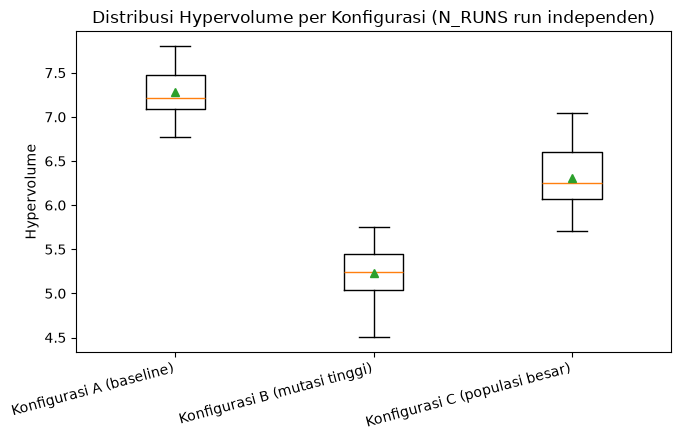

In [67]:
nama_grup = list(df_hv["konfigurasi"].unique())
data_per_grup = [df_hv[df_hv["konfigurasi"] == k]["hv"].values for k in nama_grup]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.boxplot(data_per_grup, tick_labels=nama_grup, showmeans=True)
ax.set_ylabel("Hypervolume")
ax.set_title("Distribusi Hypervolume per Konfigurasi (N_RUNS run independen)")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
fig.savefig(FIG_DIR / "01_boxplot_hv_per_konfigurasi.png", dpi=150)
plt.show()

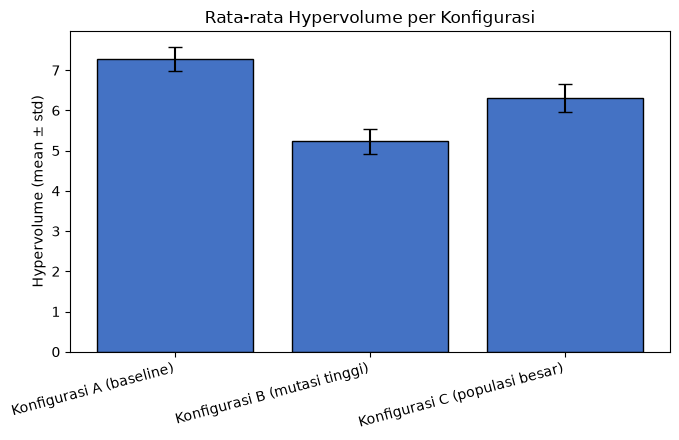

In [68]:
fig, ax = plt.subplots(figsize=(7, 4.5))
means = ringkasan["mean"].values
stds = ringkasan["std"].values
x_pos = np.arange(len(ringkasan))
ax.bar(x_pos, means, yerr=stds, capsize=5, color="#4472C4", edgecolor="black")
ax.set_xticks(x_pos)
ax.set_xticklabels(ringkasan.index, rotation=15, ha="right")
ax.set_ylabel("Hypervolume (mean ± std)")
ax.set_title("Rata-rata Hypervolume per Konfigurasi")
plt.tight_layout()
fig.savefig(FIG_DIR / "02_bar_mean_std_hv.png", dpi=150)
plt.show()

## 7. Uji Normalitas (Shapiro-Wilk)

Uji normalitas dilakukan untuk **memberi justifikasi** pemilihan uji non-parametrik
(Kruskal-Wallis/Mann-Whitney U) — bukan uji parametrik seperti ANOVA/uji-t — sebagaimana lazim pada
pengujian algoritma evolusioner, karena distribusi metrik seperti HV pada jumlah run yang terbatas
seringkali tidak normal.

In [69]:
hasil_normalitas = []
for nama_cfg in df_hv["konfigurasi"].unique():
    nilai = df_hv[df_hv["konfigurasi"] == nama_cfg]["hv"].values
    if len(nilai) >= 3:
        stat, p = stats.shapiro(nilai)
    else:
        stat, p = np.nan, np.nan
    hasil_normalitas.append({
        "konfigurasi": nama_cfg, "shapiro_stat": round(stat, 4) if not np.isnan(stat) else None,
        "p_value": round(p, 4) if not np.isnan(p) else None,
        "normal (alpha=0.05)": (p > 0.05) if not np.isnan(p) else None,
    })
df_normalitas = pd.DataFrame(hasil_normalitas)
df_normalitas

,konfigurasi,shapiro_stat,p_value,normal (alpha=0.05)
0,Konfigurasi A (baseline),0.9550,0.4498,True
1,Konfigurasi B (mutasi tinggi),0.9799,0.9328,True
2,Konfigurasi C (populasi besar),0.9803,0.9373,True


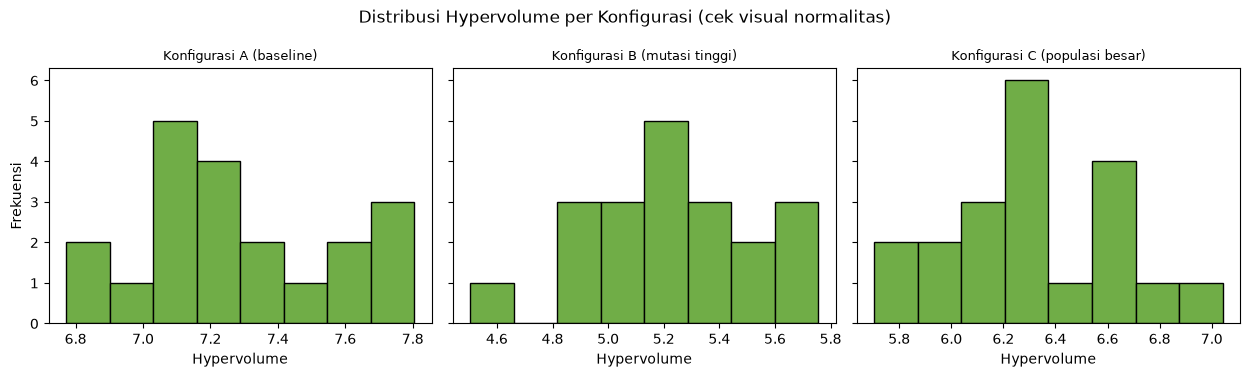

In [70]:
n_grup = len(nama_grup)
fig, axes = plt.subplots(1, n_grup, figsize=(4.2 * n_grup, 3.8), sharey=True)
if n_grup == 1:
    axes = [axes]
for ax, nama_cfg in zip(axes, nama_grup):
    nilai = df_hv[df_hv["konfigurasi"] == nama_cfg]["hv"].values
    ax.hist(nilai, bins=min(8, max(3, len(nilai) // 2)), color="#70AD47", edgecolor="black")
    ax.set_title(nama_cfg, fontsize=9)
    ax.set_xlabel("Hypervolume")
axes[0].set_ylabel("Frekuensi")
fig.suptitle("Distribusi Hypervolume per Konfigurasi (cek visual normalitas)")
plt.tight_layout()
fig.savefig(FIG_DIR / "03_histogram_normalitas.png", dpi=150)
plt.show()

## 8. Uji Kruskal-Wallis

Menguji hipotesis: **H0** — distribusi Hypervolume sama di seluruh konfigurasi (tidak ada perbedaan
signifikan) vs **H1** — setidaknya satu konfigurasi berbeda signifikan. Uji ini dipilih karena tidak
mengasumsikan distribusi normal dan cocok untuk membandingkan >2 kelompok independen.

In [71]:
grup_hv = [df_hv[df_hv["konfigurasi"] == k]["hv"].values for k in df_hv["konfigurasi"].unique()]
h_stat, p_value_kw = stats.kruskal(*grup_hv)

alpha = 0.05
signifikan_kw = p_value_kw < alpha

print(f"Statistik H Kruskal-Wallis : {h_stat:.4f}")
print(f"p-value                    : {p_value_kw:.6f}")
print(f"Signifikan pada alpha={alpha}? {'YA' if signifikan_kw else 'TIDAK'}")
print()
if signifikan_kw:
    print("Kesimpulan: terdapat perbedaan Hypervolume yang signifikan setidaknya antara "
          "sepasang konfigurasi -> lanjutkan ke uji post-hoc Mann-Whitney U (bagian 9).")
else:
    print("Kesimpulan: tidak ditemukan perbedaan Hypervolume yang signifikan antar konfigurasi "
          "pada tingkat kepercayaan yang diuji.")

Statistik H Kruskal-Wallis : 51.6790
p-value                    : 0.000000
Signifikan pada alpha=0.05? YA

Kesimpulan: terdapat perbedaan Hypervolume yang signifikan setidaknya antara sepasang konfigurasi -> lanjutkan ke uji post-hoc Mann-Whitney U (bagian 9).


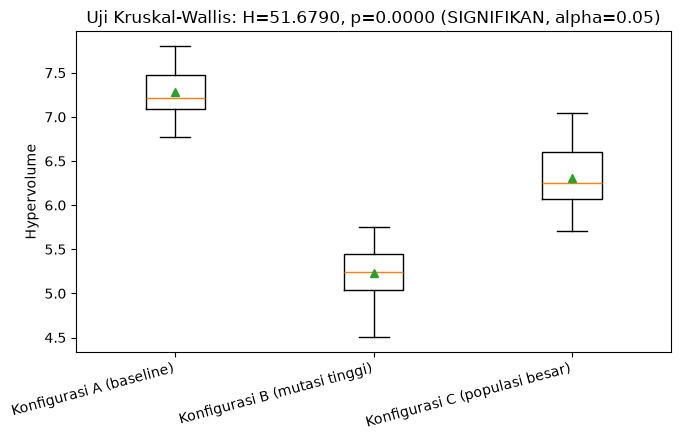

In [72]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.boxplot(data_per_grup, tick_labels=nama_grup, showmeans=True)
ax.set_ylabel("Hypervolume")
status_teks = "SIGNIFIKAN" if signifikan_kw else "TIDAK SIGNIFIKAN"
ax.set_title(f"Uji Kruskal-Wallis: H={h_stat:.4f}, p={p_value_kw:.4f} ({status_teks}, alpha={alpha})")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
fig.savefig(FIG_DIR / "04_kruskal_wallis_boxplot.png", dpi=150)
plt.show()

## 9. Uji Post-hoc Mann-Whitney U (Berpasangan)

Jika Kruskal-Wallis signifikan, uji Mann-Whitney U dilakukan untuk **setiap pasangan konfigurasi**
guna mengetahui pasangan mana yang berbeda signifikan. Karena dilakukan banyak perbandingan
sekaligus, digunakan **koreksi Bonferroni** (alpha disesuaikan = 0.05 / jumlah pasangan) untuk
menjaga tingkat kesalahan tipe I secara keseluruhan.

*Effect size* (korelasi rank-biserial, r) turut dilaporkan sebagai ukuran besar perbedaan, terlepas
dari signifikansi statistiknya.

In [73]:
nama_konfigurasi = list(df_hv["konfigurasi"].unique())
pasangan = list(itertools.combinations(nama_konfigurasi, 2))
alpha_bonferroni = alpha / len(pasangan) if pasangan else alpha

hasil_mw = []
for k1, k2 in pasangan:
    x = df_hv[df_hv["konfigurasi"] == k1]["hv"].values
    y = df_hv[df_hv["konfigurasi"] == k2]["hv"].values
    u_stat, p_val = stats.mannwhitneyu(x, y, alternative="two-sided")
    # effect size rank-biserial correlation
    n1, n2 = len(x), len(y)
    r_rb = 1 - (2 * u_stat) / (n1 * n2)
    hasil_mw.append({
        "konfigurasi_1": k1, "konfigurasi_2": k2,
        "U": u_stat, "p_value": round(p_val, 6),
        "p_adj_signifikan (Bonferroni)": p_val < alpha_bonferroni,
        "effect_size_r": round(r_rb, 4),
        "mean_hv_1": round(x.mean(), 4), "mean_hv_2": round(y.mean(), 4),
    })

df_mw = pd.DataFrame(hasil_mw)
print(f"Alpha terkoreksi Bonferroni ({len(pasangan)} pasangan): {alpha_bonferroni:.5f}")
df_mw

Alpha terkoreksi Bonferroni (3 pasangan): 0.01667


,konfigurasi_1,konfigurasi_2,U,p_value,p_adj_signifikan (Bonferroni),effect_size_r,mean_hv_1,mean_hv_2
0,Konfigurasi A (baseline),Konfigurasi B (mutasi tinggi),400.0,0.0,True,-1.000,7.2843,5.2335
1,Konfigurasi A (baseline),Konfigurasi C (populasi besar),395.0,0.0,True,-0.975,7.2843,6.3028
2,Konfigurasi B (mutasi tinggi),Konfigurasi C (populasi besar),1.0,0.0,True,0.995,5.2335,6.3028


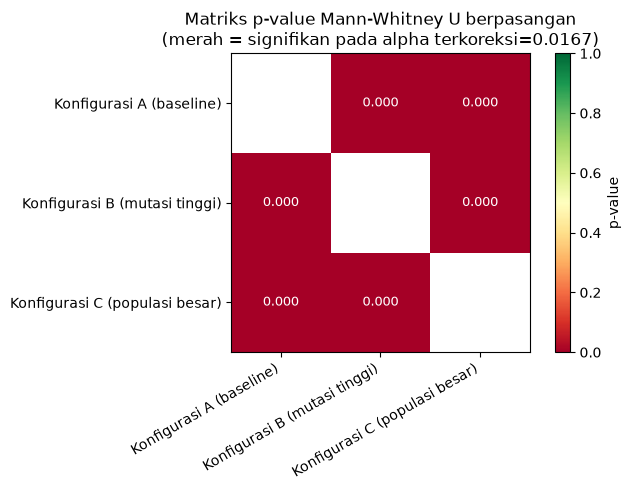

In [74]:
# Matriks p-value berpasangan (heatmap) -- diagonal dikosongkan (NaN)
matriks_p = pd.DataFrame(np.nan, index=nama_konfigurasi, columns=nama_konfigurasi)
for _, row in df_mw.iterrows():
    matriks_p.loc[row["konfigurasi_1"], row["konfigurasi_2"]] = row["p_value"]
    matriks_p.loc[row["konfigurasi_2"], row["konfigurasi_1"]] = row["p_value"]

fig, ax = plt.subplots(figsize=(5.5 + 0.5 * len(nama_konfigurasi), 5))
im = ax.imshow(matriks_p.values, cmap="RdYlGn", vmin=0, vmax=1)
ax.set_xticks(range(len(nama_konfigurasi)))
ax.set_yticks(range(len(nama_konfigurasi)))
ax.set_xticklabels(nama_konfigurasi, rotation=30, ha="right")
ax.set_yticklabels(nama_konfigurasi)
for i in range(len(nama_konfigurasi)):
    for j in range(len(nama_konfigurasi)):
        val = matriks_p.values[i, j]
        if not np.isnan(val):
            ax.text(j, i, f"{val:.3f}", ha="center", va="center", fontsize=9,
                    color="black" if val > alpha_bonferroni else "white")
fig.colorbar(im, ax=ax, label="p-value")
ax.set_title(f"Matriks p-value Mann-Whitney U berpasangan\n(merah = signifikan pada alpha "
             f"terkoreksi={alpha_bonferroni:.4f})")
plt.tight_layout()
fig.savefig(FIG_DIR / "05_heatmap_mannwhitney.png", dpi=150)
plt.show()

## 10. Ringkasan Otomatis

Sel di bawah merangkum hasil pengujian menjadi teks siap-adaptasi untuk narasi Bab 5. **Tetap
periksa dan sesuaikan kalimatnya secara manual** sebelum dimasukkan ke naskah skripsi.

In [75]:
konfigurasi_terbaik = ringkasan["mean"].idxmax()
print("=== RINGKASAN HASIL PENGUJIAN ===\n")
print(f"Jumlah konfigurasi diuji     : {len(CONFIGS)}")
print(f"Jumlah run independen/konfig : {N_RUNS}")
print(f"Titik referensi Hypervolume  : {REF_POINT}")
print(f"Konfigurasi dgn HV rata-rata tertinggi : {konfigurasi_terbaik} "
      f"(mean={ringkasan.loc[konfigurasi_terbaik, 'mean']:.4f}, "
      f"CV={ringkasan.loc[konfigurasi_terbaik, 'cv (%)']:.2f}%)\n")
print(f"Uji Kruskal-Wallis: H={h_stat:.4f}, p={p_value_kw:.6f} "
      f"-> {'terdapat' if signifikan_kw else 'tidak terdapat'} perbedaan signifikan antar konfigurasi "
      f"(alpha={alpha}).")
if signifikan_kw:
    pasangan_signifikan = df_mw[df_mw["p_adj_signifikan (Bonferroni)"]]
    if len(pasangan_signifikan):
        print("\nPasangan konfigurasi yang berbeda signifikan (post-hoc Mann-Whitney U, "
              "Bonferroni-adjusted):")
        for _, row in pasangan_signifikan.iterrows():
            print(f"  - {row['konfigurasi_1']} vs {row['konfigurasi_2']}: "
                  f"p={row['p_value']:.6f}, effect size r={row['effect_size_r']:.4f}")
    else:
        print("\nTidak ada pasangan yang tetap signifikan setelah koreksi Bonferroni "
              "(meski Kruskal-Wallis keseluruhan signifikan).")

=== RINGKASAN HASIL PENGUJIAN ===

Jumlah konfigurasi diuji     : 3
Jumlah run independen/konfig : 20
Titik referensi Hypervolume  : (1.91345, 5.94616)
Konfigurasi dgn HV rata-rata tertinggi : Konfigurasi A (baseline) (mean=7.2843, CV=4.15%)

Uji Kruskal-Wallis: H=51.6790, p=0.000000 -> terdapat perbedaan signifikan antar konfigurasi (alpha=0.05).

Pasangan konfigurasi yang berbeda signifikan (post-hoc Mann-Whitney U, Bonferroni-adjusted):
  - Konfigurasi A (baseline) vs Konfigurasi B (mutasi tinggi): p=0.000000, effect size r=-1.0000
  - Konfigurasi A (baseline) vs Konfigurasi C (populasi besar): p=0.000000, effect size r=-0.9750
  - Konfigurasi B (mutasi tinggi) vs Konfigurasi C (populasi besar): p=0.000000, effect size r=0.9950


## 11. Rekomendasi Menu dan Grafik Pareto Front (Konfigurasi Terbaik)

Berdasarkan hasil pengujian di atas, konfigurasi dengan Hypervolume rata-rata tertinggi
(`konfigurasi_terbaik`) dipakai untuk menampilkan:

1. **Grafik Pareto front** — sebaran solusi non-dominated (rank-1) dari run terbaik konfigurasi
   tersebut, dengan solusi rekomendasi ditandai.
2. **Tabel rekomendasi menu 10 hari** — hasil pemilihan solusi (leksikografis f2 lalu f1, sesuai
   `MBGOptimizer.run()`) dari run tersebut, lengkap dengan status pemenuhan gizi tiap hari.

Run yang dipakai adalah run dengan Hypervolume tertinggi **di dalam** `konfigurasi_terbaik`
(front paling baik/representatif dari konfigurasi tersebut).

In [76]:
# Pilih run terbaik (HV tertinggi) di dalam konfigurasi_terbaik
run_terbaik = max(
    (r for r in raw_results if r["konfigurasi"] == konfigurasi_terbaik),
    key=lambda r: r["hv"],
)
solusi_rekomendasi = run_terbaik["best"]

print(f"Konfigurasi terbaik : {konfigurasi_terbaik}")
print(f"Run ke-             : {run_terbaik['run'] + 1} (seed={run_terbaik['seed']})")
print(f"Hypervolume run ini  : {run_terbaik['hv']:.4f}")
print(f"f1 (deviasi gizi)    : {solusi_rekomendasi['f1']}")
print(f"f2 (penalti ulang)   : {solusi_rekomendasi['f2']}")
print(f"Feasible             : {solusi_rekomendasi['feasible']} "
      f"(fallback={solusi_rekomendasi['fallback']})")

Konfigurasi terbaik : Konfigurasi A (baseline)
Run ke-             : 6 (seed=563627)
Hypervolume run ini  : 7.8048
f1 (deviasi gizi)    : 0.7521
f2 (penalti ulang)   : 0.0
Feasible             : True (fallback=False)


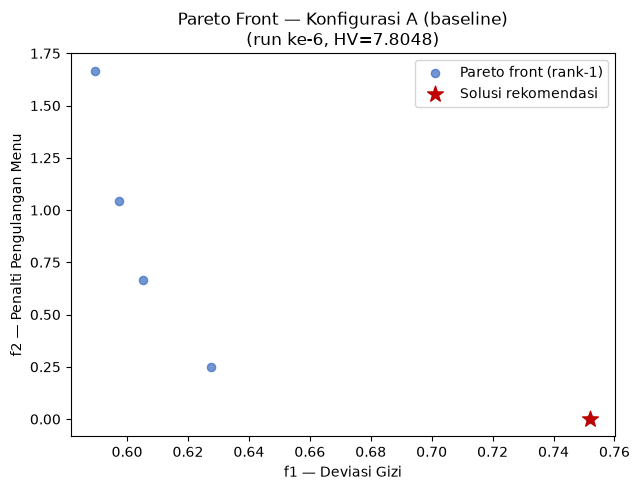

In [77]:
fig, ax = plt.subplots(figsize=(6.5, 5))
f1_front = [p[0] for p in run_terbaik["front1_points"]]
f2_front = [p[1] for p in run_terbaik["front1_points"]]
ax.scatter(f1_front, f2_front, s=35, color="#4472C4", alpha=0.75, label="Pareto front (rank-1)")
ax.scatter([solusi_rekomendasi["f1"]], [solusi_rekomendasi["f2"]], s=140, color="#C00000",
           marker="*", zorder=5, label="Solusi rekomendasi")
ax.set_xlabel("f1 — Deviasi Gizi")
ax.set_ylabel("f2 — Penalti Pengulangan Menu")
ax.set_title(f"Pareto Front — {konfigurasi_terbaik}\n(run ke-{run_terbaik['run'] + 1}, "
             f"HV={run_terbaik['hv']:.4f})")
ax.legend()
plt.tight_layout()
fig.savefig(FIG_DIR / "06_pareto_front_terbaik.png", dpi=150)
plt.show()

In [78]:
# Susun tabel rekomendasi menu 10 hari dari solusi terpilih
baris_menu = []
for hari in solusi_rekomendasi["menu"]:
    baris = {
        "hari": hari["hari"],
        "pokok": hari["pokok"]["nama"],
        "lauk": hari["lauk"]["nama"],
        "sayur": hari["sayur"]["nama"],
        "buah": hari["buah"]["nama"],
        "minuman": hari["minuman"]["nama"],
    }
    for k in NUT_COLS:
        baris[f"{k}_nilai"] = hari["gizi"][k]["nilai"]
        baris[f"{k}_status"] = hari["gizi"][k]["status"]
    baris_menu.append(baris)

df_rekomendasi_menu = pd.DataFrame(baris_menu)
df_rekomendasi_menu

,hari,pokok,lauk,sayur,buah,minuman,energi_nilai,energi_status,protein_nilai,protein_status,lemak_nilai,lemak_status,karbo_nilai,karbo_status
0,1,nasi tim daging,pempek kulit,tumis bayam and sawi belu,jambu air,Susu UHT 200 ml,725.6,terpenuhi,22.4,terpenuhi,24.5,terpenuhi,104.0,terpenuhi
1,2,ketupat tahu,perkedel jagung,tumis kangkung belu,jambu biji,Susu UHT 200 ml,716.3,terpenuhi,22.6,terpenuhi,23.8,terpenuhi,107.9,terpenuhi
2,3,mie ayam,udang asam manis,tumis bayam belu,rambutan,Susu UHT 200 ml,731.5,terpenuhi,23.5,terpenuhi,24.3,terpenuhi,105.8,terpenuhi
3,4,nasi jagung,sardines,urap,Pear fresh,Susu UHT 200 ml,702.9,terpenuhi,21.0,terpenuhi,24.6,terpenuhi,105.5,terpenuhi
4,5,nasi liwet,kalio ayam,bening selada air and kangkung belu,jus alpukat,Susu UHT 200 ml,722.5,terpenuhi,21.9,terpenuhi,24.8,terpenuhi,103.3,terpenuhi
5,6,mie bakso,semur jengkol,tumis selada air belu,nangka masak di pohon,Susu UHT 200 ml,713.1,terpenuhi,22.0,terpenuhi,24.1,terpenuhi,106.8,terpenuhi
6,7,nasi merah,tempe goreng,sayur sop,srikaya,Susu UHT 200 ml,682.6,terpenuhi,22.2,terpenuhi,23.6,terpenuhi,100.8,terpenuhi
7,8,nasi uduk,maklor,tumis terong belu,nanas,Susu UHT 200 ml,702.5,terpenuhi,22.3,terpenuhi,24.0,terpenuhi,99.3,terpenuhi
8,9,bacang,udang goreng,capcai,jus alpukat,Susu UHT 200 ml,723.6,terpenuhi,21.4,terpenuhi,24.7,terpenuhi,103.7,terpenuhi
9,10,nasi goreng ayam suwir,rawon,terong balado,jus melon,Susu UHT 200 ml,720.9,terpenuhi,21.1,terpenuhi,24.3,terpenuhi,105.9,terpenuhi


## 12. Ekspor Semua Tabel + Grafik ke Excel

Sel di bawah menulis satu file **`hasil_ekspor/bab5_hasil_uji_statistik.xlsx`** berisi enam sheet
(tabel hasil tiap uji + grafik yang sudah dibuat di atas), siap dilampirkan langsung ke laporan:

1. **Ringkasan Deskriptif** — tabel statistik + boxplot + bar chart mean±std
2. **Uji Normalitas** — tabel Shapiro-Wilk + histogram per konfigurasi
3. **Kruskal-Wallis** — hasil uji + boxplot beranotasi
4. **Mann-Whitney** — tabel berpasangan + heatmap p-value
5. **Data Mentah HV** — nilai Hypervolume tiap run individual (data pendukung/lampiran)
6. **Rekomendasi Menu** — grafik Pareto front + tabel menu 10 hari dari konfigurasi terbaik

In [79]:
from openpyxl import Workbook
from openpyxl.styles import Font, Alignment, PatternFill, Border, Side
from openpyxl.drawing.image import Image as XLImage
from openpyxl.utils import get_column_letter

FONT_NAME = "Arial"
header_font = Font(name=FONT_NAME, bold=True, color="FFFFFF", size=10)
header_fill = PatternFill("solid", fgColor="4472C4")
title_font = Font(name=FONT_NAME, bold=True, size=13)
normal_font = Font(name=FONT_NAME, size=10)
thin_side = Side(style="thin", color="B7B7B7")
thin_border = Border(left=thin_side, right=thin_side, top=thin_side, bottom=thin_side)


def _ke_native(val):
    if isinstance(val, (np.floating,)):
        return float(val)
    if isinstance(val, (np.integer,)):
        return int(val)
    if isinstance(val, (np.bool_,)):
        return bool(val)
    return val


def tulis_tabel(ws, df, start_row, start_col=1, title=None, sertakan_index=True,
                 nama_kolom_index="konfigurasi"):
    r = start_row
    if title:
        ws.cell(row=r, column=start_col, value=title).font = title_font
        r += 2
    kolom = ([nama_kolom_index] if sertakan_index else []) + list(df.columns)
    header_row = r
    for j, col in enumerate(kolom):
        c = ws.cell(row=header_row, column=start_col + j, value=str(col))
        c.font = header_font
        c.fill = header_fill
        c.alignment = Alignment(horizontal="center")
        c.border = thin_border
    for i, (idx, row) in enumerate(df.iterrows()):
        data_row = ([idx] if sertakan_index else []) + [row[c] for c in df.columns]
        for j, val in enumerate(data_row):
            c = ws.cell(row=header_row + 1 + i, column=start_col + j, value=_ke_native(val))
            c.font = normal_font
            c.border = thin_border
    for j, col in enumerate(kolom):
        letter = get_column_letter(start_col + j)
        if j == 0 and sertakan_index:
            lebar_data = [len(str(idx)) for idx, _ in df.iterrows()] if len(df) else [0]
        else:
            lebar_data = [len(str(row[col])) for _, row in df.iterrows()] if len(df) else [0]
        maxlen = max([len(str(col))] + lebar_data)
        ws.column_dimensions[letter].width = min(max(maxlen + 2, 10), 42)
    return header_row + 1 + len(df)


wb = Workbook()
wb.remove(wb.active)

# --- Sheet 1: Ringkasan Deskriptif ---
ws1 = wb.create_sheet("1. Ringkasan Deskriptif")
baris_akhir = tulis_tabel(ws1, ringkasan, start_row=1,
                           title="Statistik Deskriptif Hypervolume per Konfigurasi")
ws1.add_image(XLImage(str(FIG_DIR / "01_boxplot_hv_per_konfigurasi.png")),
              f"A{baris_akhir + 2}")
ws1.add_image(XLImage(str(FIG_DIR / "02_bar_mean_std_hv.png")),
              f"A{baris_akhir + 26}")

# --- Sheet 2: Uji Normalitas ---
ws2 = wb.create_sheet("2. Uji Normalitas")
df_normalitas_idx = df_normalitas.set_index("konfigurasi")
baris_akhir2 = tulis_tabel(ws2, df_normalitas_idx, start_row=1,
                            title="Uji Normalitas Shapiro-Wilk (per Konfigurasi)")
ws2.add_image(XLImage(str(FIG_DIR / "03_histogram_normalitas.png")), f"A{baris_akhir2 + 2}")

# --- Sheet 3: Kruskal-Wallis ---
ws3 = wb.create_sheet("3. Kruskal-Wallis")
df_kw = pd.DataFrame([{
    "H_statistik": round(h_stat, 4), "p_value": round(p_value_kw, 6),
    "alpha": alpha, "signifikan": bool(signifikan_kw),
    "jumlah_konfigurasi": len(CONFIGS), "run_per_konfigurasi": N_RUNS,
}]).set_index(pd.Index(["Hasil Uji"]))
baris_akhir3 = tulis_tabel(ws3, df_kw, start_row=1, title="Hasil Uji Kruskal-Wallis",
                            nama_kolom_index="")
ws3.add_image(XLImage(str(FIG_DIR / "04_kruskal_wallis_boxplot.png")), f"A{baris_akhir3 + 2}")

# --- Sheet 4: Mann-Whitney ---
ws4 = wb.create_sheet("4. Mann-Whitney")
df_mw_tampil = df_mw.rename(columns={"p_adj_signifikan (Bonferroni)": "signifikan_bonferroni"})
baris_akhir4 = tulis_tabel(ws4, df_mw_tampil.set_index(pd.Index(range(1, len(df_mw_tampil) + 1))),
                            start_row=1,
                            title=f"Uji Post-hoc Mann-Whitney U (alpha terkoreksi={alpha_bonferroni:.5f})",
                            nama_kolom_index="no")
ws4.add_image(XLImage(str(FIG_DIR / "05_heatmap_mannwhitney.png")), f"A{baris_akhir4 + 2}")

# --- Sheet 5: Data Mentah HV (lampiran) ---
ws5 = wb.create_sheet("5. Data Mentah HV")
df_hv_tampil = df_hv.rename(columns={"hv": "hypervolume"})
tulis_tabel(ws5, df_hv_tampil.set_index(pd.Index(range(1, len(df_hv_tampil) + 1))), start_row=1,
            title="Hypervolume per Run Individual (seluruh konfigurasi)", nama_kolom_index="no")

# --- Sheet 6: Rekomendasi Menu (konfigurasi terbaik) ---
ws6 = wb.create_sheet("6. Rekomendasi Menu")
ws6.cell(row=1, column=1,
         value=f"Rekomendasi Menu 10 Hari — {konfigurasi_terbaik} "
               f"(run ke-{run_terbaik['run'] + 1}, HV={run_terbaik['hv']:.4f}, "
               f"f1={solusi_rekomendasi['f1']}, f2={solusi_rekomendasi['f2']})").font = title_font
ws6.add_image(XLImage(str(FIG_DIR / "06_pareto_front_terbaik.png")), "A3")
baris_akhir6 = tulis_tabel(ws6, df_rekomendasi_menu.set_index("hari"), start_row=32,
                            title="Tabel Menu 10 Hari (Solusi Rekomendasi)",
                            nama_kolom_index="hari")

wb.save(XLSX_PATH)
print(f"File Excel tersimpan di: {XLSX_PATH.resolve()}")

File Excel tersimpan di: D:\uji nsga\hasil_ekspor\bab5_hasil_uji_statistik.xlsx
